# Survival Lab

We've looked at normal-linear regression and probit regression from a likelihood perspective, which yields two log-likelihoods:
$$
LL(\beta,\sigma) = - n \log( \sqrt{2\pi} ) - n \log(\sigma) - \frac{1}{2\sigma^2} \sum_{i=1}^n (y_i - x_i \beta)^2
$$
and
$$
LL(\beta) = \sum_{i=1}^N y_i \log(\Phi(x_i \cdot \beta/\sigma)) + (1-y_i) \log(1-\Phi(x_i \cdot \beta/\sigma)).
$$
This lab combines them by looking at **right-censored** survival data.

We are going to use the Metabric breast cancer dataset to predict how long someone survives after being treated for breast cancer. For the regressions that follow, include the following as numeric variables:

- 'Age at Diagnosis'
- 'Lymph nodes examined positive'
- 'Mutation Count'
- 'Tumor Size'

and the following as categorical variables (one-hot encode them):

- 'Chemotherapy'
- 'Hormone Therapy'
- 'Radio Therapy'
- 'Tumor Stage'

The outcome variable of interest is the log of `Overall Survival (Months)`, which we'll refer to as log-months.

1. Load the `./data/metabric.csv` data. Tabulate `Overall Survival Status` to see who is alive or dead at the time the study ends. Make a kernel density plot of `Overall Survival (Months)`, hued by `Overall Survival Status`, to see the difference between survival duration for those alive and those dead at the time the study ended. **Drop the observations for which `Tumor Stage` is zero.**
2. Use Scikit's `train_test_split` with a `test_size` of .2. There are two tempting -- but ultimately incorrect -- ways to handle the Survival Status issue:
    - Use the reported `Overall Survival (Months)` as the target variable
    - Drop everyone who is alive at the time the study ends
Run these flawed regressions and save the coefficients and test-set predictions. Explain clearly how the first option is an example of imputation and the second treats survival as missing data.
3. Derive the log-likelihood for a model where the normal density is used for log-months when the subject died during the study (and log-months is observed, as in linear-normal regression), and the survival probability based on the Normal distribution is used when the patient is alive when the study ends (and log-months is a latent variable, as in a binary probit).
4. We want to estimate the model in part 3. You can do this with the `lifelines` package's `LogNormalAFTFitter`, or use the code chunk below to extend StatsModels to estimate this kind of model.
5. Compare the coefficients and test-set predictions (be careful to keep an eye on the censoring) for the censored MLE and the two linear models. Can you identify any groups who receive systematically biased predictions from the imputation and missing data approaches? 

# Step 1

In [194]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
import statsmodels.formula.api as smf
from statsmodels.base.model import GenericLikelihoodModel
from scipy.stats import norm


* Probit for living, linear for deceased, put them together to create likelihood function.

In [195]:
metabric = pd.read_csv('./data/metabric.csv')

metabric.head(3)

,Age at Diagnosis,Type of Breast Surgery,Cancer Type,Chemotherapy,Hormone Therapy,Lymph nodes examined positive,Mutation Count,Nottingham prognostic index,Overall Survival (Months),Overall Survival Status,Radio Therapy,TMB (nonsynonymous),Tumor Size,Tumor Stage
0,43.19,BREAST CONSERVING,Breast Cancer,NO,YES,0.0,2.0,4.02,84.633333,0:LIVING,YES,2.615035,10.0,1.0
1,48.87,MASTECTOMY,Breast Cancer,YES,YES,1.0,2.0,4.03,163.700000,1:DECEASED,NO,2.615035,15.0,2.0
2,47.68,MASTECTOMY,Breast Cancer,YES,YES,3.0,1.0,4.05,164.933333,0:LIVING,YES,1.307518,25.0,2.0


In [196]:
metabric.groupby('Overall Survival Status')['Overall Survival (Months)'].agg('mean')

Overall Survival Status
0:LIVING      166.050145
1:DECEASED    101.425521
Name: Overall Survival (Months), dtype: float64

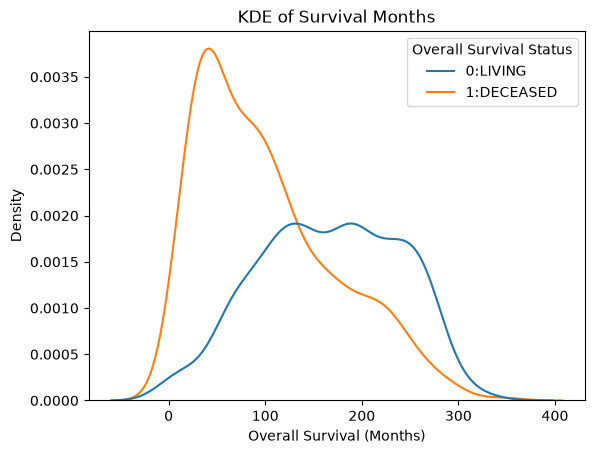

In [197]:
sns.kdeplot(metabric, x= 'Overall Survival (Months)', hue='Overall Survival Status')
plt.title('KDE of Survival Months')
plt.show()

In [198]:
metabric = metabric[metabric['Tumor Stage'] != 0]
metabric['Tumor Stage'].value_counts()


Tumor Stage
2.0    767
1.0    458
3.0    109
4.0      7
Name: count, dtype: int64

# Step 2: Flawed Models

## First linear model, all observations

In [199]:
train, test = train_test_split(metabric, test_size=0.2, random_state = 42)
model = smf.ols(
    'np.log(Q("Overall Survival (Months)")) ~ Q("Age at Diagnosis") + Q("Lymph nodes examined positive") + Q("Mutation Count") + Q("Tumor Size") '\
    '+ C(Q("Chemotherapy")) + C(Q("Hormone Therapy")) + C(Q("Radio Therapy")) + C(Q("Tumor Stage"))', 
    data = train,
).fit()
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                                      OLS Regression Results                                      
==================================================================================================
Dep. Variable:     np.log(Q("Overall Survival (Months)"))   R-squared:                       0.121
Model:                                                OLS   Adj. R-squared:                  0.113
Method:                                     Least Squares   F-statistic:                     14.60
Date:                                    Tue, 17 Nov 2026   Prob (F-statistic):           1.48e-24
Time:                                            15:14:53   Log-Likelihood:                -1329.2
No. Observations:                                    1072   AIC:                             2680.
Df Residuals:                                        1061   BIC:                             2735.
Df Model:                                              10                                         
Covariance Type:                                nonrobust                                         
======================================================================================================
                                         coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------------
Intercept                              5.2934      0.156     33.959      0.000       4.987       5.599
C(Q("Chemotherapy"))[T.YES]           -0.2191      0.081     -2.719      0.007      -0.377      -0.061
C(Q("Hormone Therapy"))[T.YES]         0.0864      0.059      1.475      0.140      -0.029       0.201
C(Q("Radio Therapy"))[T.YES]           0.1202      0.057      2.107      0.035       0.008       0.232
C(Q("Tumor Stage"))[T.2.0]            -0.1872      0.066     -2.832      0.005      -0.317      -0.057
C(Q("Tumor Stage"))[T.3.0]            -0.4052      0.130     -3.116      0.002      -0.660      -0.150
C(Q("Tumor Stage"))[T.4.0]            -0.7073      0.387     -1.827      0.068      -1.467       0.052
Q("Age at Diagnosis")                 -0.0086      0.002     -3.670      0.000      -0.013      -0.004
Q("Lymph nodes examined positive")    -0.0384      0.008     -4.891      0.000      -0.054      -0.023
Q("Mutation Count")                    0.0064      0.007      0.952      0.341      -0.007       0.020
Q("Tumor Size")                       -0.0038      0.002     -1.680      0.093      -0.008       0.001
==============================================================================
Omnibus:                      416.074   Durbin-Watson:                   2.016
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             2370.769
Skew:                          -1.692   Prob(JB):                         0.00
Kurtosis:                       9.452   Cond. No.                     1.02e+03
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 1.02e+03. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

In [200]:
param_df = pd.DataFrame({'model1': model.params})
param_df

,model1
Intercept,5.293352
"C(Q(""Chemotherapy""))[T.YES]",-0.219118
"C(Q(""Hormone Therapy""))[T.YES]",0.086354
"C(Q(""Radio Therapy""))[T.YES]",0.120239
"C(Q(""Tumor Stage""))[T.2.0]",-0.187168
"C(Q(""Tumor Stage""))[T.3.0]",-0.405198
"C(Q(""Tumor Stage""))[T.4.0]",-0.707348
"Q(""Age at Diagnosis"")",-0.008551
"Q(""Lymph nodes examined positive"")",-0.038357
"Q(""Mutation Count"")",0.006382


In [201]:
prediction = model.get_prediction(test).summary_frame()['mean']

prediction_df = pd.DataFrame({'model1': prediction})
prediction_df

,model1
0,4.779502
1,4.985947
2,4.630981
3,4.775639
4,4.388073
...,...
264,4.286563
265,4.704388
266,4.751924
267,4.536372


## Second model, dropping everyone alive when the study ends

In [202]:
train2 = train[train['Overall Survival Status'] == '1:DECEASED']

model2 = smf.ols(
    'np.log(Q("Overall Survival (Months)")) ~ Q("Age at Diagnosis") + Q("Lymph nodes examined positive") + Q("Mutation Count") + Q("Tumor Size") '\
    '+ C(Q("Chemotherapy")) + C(Q("Hormone Therapy")) + C(Q("Radio Therapy")) + C(Q("Tumor Stage"))', 
    data = train2,
).fit()
model2.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                                      OLS Regression Results                                      
==================================================================================================
Dep. Variable:     np.log(Q("Overall Survival (Months)"))   R-squared:                       0.152
Model:                                                OLS   Adj. R-squared:                  0.138
Method:                                     Least Squares   F-statistic:                     10.81
Date:                                    Tue, 17 Nov 2026   Prob (F-statistic):           5.18e-17
Time:                                            15:14:53   Log-Likelihood:                -764.43
No. Observations:                                     615   AIC:                             1551.
Df Residuals:                                         604   BIC:                             1600.
Df Model:                                              10                                         
Covariance Type:                                nonrobust                                         
======================================================================================================
                                         coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------------
Intercept                              4.6594      0.219     21.301      0.000       4.230       5.089
C(Q("Chemotherapy"))[T.YES]           -0.3931      0.113     -3.490      0.001      -0.614      -0.172
C(Q("Hormone Therapy"))[T.YES]         0.2423      0.080      3.037      0.002       0.086       0.399
C(Q("Radio Therapy"))[T.YES]           0.0392      0.074      0.532      0.595      -0.106       0.184
C(Q("Tumor Stage"))[T.2.0]            -0.2238      0.089     -2.501      0.013      -0.400      -0.048
C(Q("Tumor Stage"))[T.3.0]            -0.5528      0.156     -3.544      0.000      -0.859      -0.246
C(Q("Tumor Stage"))[T.4.0]            -1.0499      0.436     -2.407      0.016      -1.906      -0.193
Q("Age at Diagnosis")                 -0.0029      0.003     -0.946      0.345      -0.009       0.003
Q("Lymph nodes examined positive")    -0.0279      0.009     -3.124      0.002      -0.046      -0.010
Q("Mutation Count")                    0.0096      0.008      1.209      0.227      -0.006       0.025
Q("Tumor Size")                       -0.0018      0.003     -0.692      0.489      -0.007       0.003
==============================================================================
Omnibus:                      210.630   Durbin-Watson:                   1.891
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             1313.803
Skew:                          -1.375   Prob(JB):                    5.14e-286
Kurtosis:                       9.611   Cond. No.                         912.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [203]:
param_df['model2'] = model2.params
param_df

,model1,model2
Intercept,5.293352,4.659419
"C(Q(""Chemotherapy""))[T.YES]",-0.219118,-0.393093
"C(Q(""Hormone Therapy""))[T.YES]",0.086354,0.242348
"C(Q(""Radio Therapy""))[T.YES]",0.120239,0.039192
"C(Q(""Tumor Stage""))[T.2.0]",-0.187168,-0.223816
"C(Q(""Tumor Stage""))[T.3.0]",-0.405198,-0.552826
"C(Q(""Tumor Stage""))[T.4.0]",-0.707348,-1.049910
"Q(""Age at Diagnosis"")",-0.008551,-0.002901
"Q(""Lymph nodes examined positive"")",-0.038357,-0.027944
"Q(""Mutation Count"")",0.006382,0.009611


In [204]:
prediction = model2.get_prediction(test).summary_frame()['mean']
prediction_df['model2'] = prediction

prediction_df


,model1,model2
0,4.779502,4.497828
1,4.985947,4.612540
2,4.630981,4.480401
3,4.775639,4.504458
4,4.388073,3.995049
...,...,...
264,4.286563,4.082466
265,4.704388,4.508507
266,4.751924,4.560876
267,4.536372,4.478662


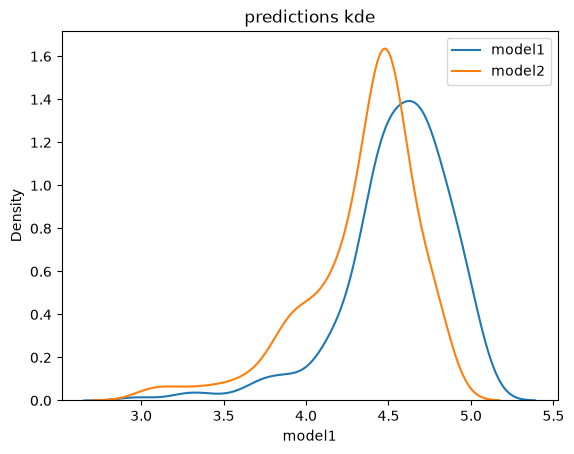

In [205]:
sns.kdeplot(prediction_df['model1'], label = 'model1')
sns.kdeplot(prediction_df['model2'], label = 'model2')
plt.legend()
plt.title('predictions kde')
plt.show()

**Answers to question 2**
* If the participant did not die during the study, then their 'death' is assigned to be at the end of the study. This is imputation because the participants actual death-date is unknown. Any unknown that is replaced with a 'guess' is imputation; in this case unknown death -> end of the study. This skews the data, and the model predicts lower life expectancy than there would actually be.
* The second regression does not make use of any of the information that could be useful in the survived observations because it drops all observations where the participant is marked as survived (therefore it treats survival as missing information). It only trains on people who died, which is not an accurate representation of everyone in the sample.

# Step 3

**Given Individual Log Likelihoods**
* LL Normal-Linear
$$
LL(\beta,\sigma) = - n \log( \sqrt{2\pi} ) - n \log(\sigma) - \frac{1}{2\sigma^2} \sum_{i=1}^n (y_i - x_i \beta)^2
$$
and
* LL Probit
$$
LL(\beta) = \sum_{i=1}^N y_i \log(\Phi(x_i \cdot \beta/\sigma)) + (1-y_i) \log(1-\Phi(x_i \cdot \beta/\sigma)).
$$
* Combine them using an indicator $d_i = 1$: Dead at end of study, $d_i = 0$: Not dead at end of study. This gets
$$
LL(\beta,\sigma) = \sum_{i=1}^n d_i (LL Normal Linear) + \sum_{i=1}^n (1-d_i) (LL Probit)
$$


# Step 4

In [206]:
# Setup
ols_all = model
y_train = pd.DataFrame(ols_all.model.endog)
X_train = pd.DataFrame(ols_all.model.exog, columns = ols_all.model.exog_names)
train['event'] = (train['Overall Survival Status']=='1:DECEASED').astype(int)

In [207]:
class CensoredNormalMLE(GenericLikelihoodModel):
    def __init__(self, endog, exog, event):
        super().__init__(endog, exog, extra_params_names=["log_sigma"])
        self.event = np.asarray(event)

    def nloglikeobs(self, params):
        beta, log_sigma = params[:-1], params[-1]
        sigma = np.exp(log_sigma)
        z = (self.endog - self.exog @ beta) / sigma
        ll_dead = norm.logpdf(z) - log_sigma
        ll_alive = norm.logsf(z)
        return -np.where(self.event == 1, ll_dead, ll_alive)


start = np.r_[ols_all.params, np.log(np.sqrt(np.mean(ols_all.resid ** 2)))]

model3 = CensoredNormalMLE(y_train, X_train, train["event"])
mle = model3.fit(start_params=start, method="bfgs", maxiter=1000, disp=False)

print("Converged:", mle.mle_retvals["converged"])
print(mle.summary())

Converged: True
                          CensoredNormalMLE Results                           
Dep. Variable:                      0   Log-Likelihood:                -1201.4
Model:              CensoredNormalMLE   AIC:                             2427.
Method:            Maximum Likelihood   BIC:                             2487.
Date:                Tue, 17 Nov 2026                                         
Time:                        15:14:54                                         
No. Observations:                1072                                         
Df Residuals:                    1060                                         
Df Model:                          10                                         
                                         coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------------------
Intercept                              6.7612      0.232     29.142

In [208]:
param_df['model3'] = mle.params[:-1]
param_df

,model1,model2,model3
Intercept,5.293352,4.659419,6.761228
"C(Q(""Chemotherapy""))[T.YES]",-0.219118,-0.393093,-0.272630
"C(Q(""Hormone Therapy""))[T.YES]",0.086354,0.242348,0.261282
"C(Q(""Radio Therapy""))[T.YES]",0.120239,0.039192,0.213519
"C(Q(""Tumor Stage""))[T.2.0]",-0.187168,-0.223816,-0.322433
"C(Q(""Tumor Stage""))[T.3.0]",-0.405198,-0.552826,-0.553192
"C(Q(""Tumor Stage""))[T.4.0]",-0.707348,-1.049910,-0.846785
"Q(""Age at Diagnosis"")",-0.008551,-0.002901,-0.021836
"Q(""Lymph nodes examined positive"")",-0.038357,-0.027944,-0.056686
"Q(""Mutation Count"")",0.006382,0.009611,-0.016831


<Axes: xlabel='coef', ylabel='param'>

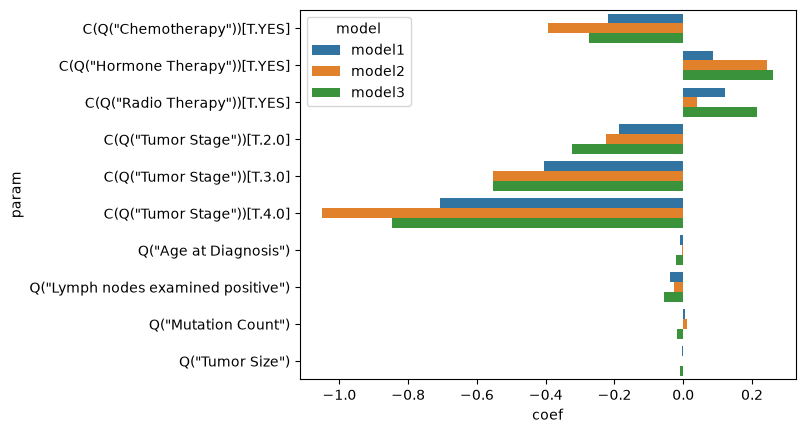

In [228]:
plot_df = (param_df
           .rename_axis('param')
            .drop('Intercept')
           .reset_index()
           .melt(id_vars='param', var_name='model', value_name='coef'))

sns.barplot(plot_df, y='param', x='coef', hue='model')

* Overall comparison: Comparing the linear regressions with the lognormal model coefficients, it seems consistent that worse cancers correspond with higher decreases in log months. Consistently, chemotherapy is not good for survival.
* Bias: It seems that the positive effect of radio therapy is understated by the linear models when considering those who lived after the study ended, especially with comparison to model 2 (where we dropped all these observations). We see a similiar (although smaller) effect with age, which could suggest that young people are under-represented in the first two models because they were more likely to survive past when the study ended. It seems that people treated with radio therapy and age are two groups are biased in the earlier models.

# Statement on AI
* I used AI to help explain the concepts behind question 3 becuase I was confused what the question was asking.
* I also used AI to help explain to me what to import to run the provided code and how to pass the training data to that code so I would stop getting errors.